# 04 · POS Tagging and Named Entity Recognition (Module II)

**Theory.** *Part-of-speech tagging* labels each token with its grammatical role (NOUN, VERB, ADJ…).
It is a sequence-labelling task, because the right tag depends on the neighbours ("book a flight" vs
"a good book"). *Named Entity Recognition* finds spans that name things and types them (PERSON, ORG,
GPE = countries/cities/states, DATE, MONEY…). spaCy's `en_core_web_sm` is a small CNN trained on the
OntoNotes 5 news corpus. NLTK's tagger is an averaged perceptron trained on the Penn Treebank.
Both are statistical, so they make mistakes, especially on ambiguous or unseen names.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import time
from collections import Counter
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from spacy import displacy

from src.utils import DATA, FAST, SEED
from src.data import BBC_LABELS, load
from src.evaluate import save_results

pd.set_option("display.max_colwidth", 150)
nlp = spacy.load("en_core_web_sm")
print("pipeline:", nlp.pipe_names)

pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## Run spaCy over every BBC article body
The dependency parser is switched off here (nb08 uses it); tagging and NER do not need it.

In [2]:
bbc = load("bbc")
if FAST:
    bbc = bbc.groupby("category").head(60)
t0 = time.perf_counter()
pos_rows, ent_rows = [], []
with nlp.select_pipes(disable=["parser", "lemmatizer"]):
    for (aid, cat), doc in zip(zip(bbc.id, bbc.category), nlp.pipe(bbc.body, batch_size=64)):
        pos_rows.append({"id": aid, "category": cat, **Counter(t.pos_ for t in doc if not t.is_space)})
        for e in doc.ents:
            ent_rows.append({"id": aid, "category": cat, "text": e.text, "label": e.label_,
                             "start_char": e.start_char, "end_char": e.end_char})
secs = time.perf_counter() - t0
pos = pd.DataFrame(pos_rows).fillna(0)
ents = pd.DataFrame(ent_rows)
n_tokens = int(pos.drop(columns=["id", "category"]).to_numpy().sum())
print(f"{len(bbc):,} articles, {n_tokens:,} tokens, {len(ents):,} entities in {secs:.1f}s "
      f"({n_tokens / secs:,.0f} tokens/s)")

2,089 articles, 924,743 tokens, 83,859 entities in 95.2s (9,710 tokens/s)


In [3]:
if not FAST:  # a FAST run must not replace the full file used by later notebooks
    ents.to_parquet(DATA / "entities.parquet", index=False)
    print("saved data/entities.parquet")
ents.head()

saved data/entities.parquet


,id,category,text,label,start_char,end_char
0,0,politics,Gordon Brown,PERSON,0,12
1,0,politics,Labour,ORG,59,65
2,0,politics,third,ORDINAL,78,83
3,0,politics,Budget,ORG,125,131
4,0,politics,1230,DATE,135,139


## POS distribution per category
Share of all tokens in each category, for the 11 most common tags (%).

In [4]:
tags = pos.drop(columns=["id", "category"]).sum().sort_values(ascending=False).index[:11]
totals = pos.drop(columns="id").groupby("category").sum()          # tag counts per category
pos_share = (totals[tags].div(totals.sum(axis=1), axis=0) * 100).round(1)
pos_share

,NOUN,PUNCT,VERB,ADP,PROPN,DET,ADJ,AUX,PRON,ADV,PART
category,,,,,,,,,,,
business,20.8,11.3,10.4,11.1,9.4,8.9,6.8,5.3,2.9,2.8,3.0
entertainment,17.0,12.1,9.7,10.3,13.2,9.0,5.9,5.5,4.9,2.8,2.8
politics,18.0,11.2,11.3,10.2,9.6,9.3,6.2,6.9,5.3,2.9,3.4
sport,14.2,12.8,9.8,10.0,13.2,8.4,5.6,6.3,6.4,3.4,3.1
tech,21.1,11.2,11.0,10.5,6.6,8.9,7.1,6.5,4.6,3.6,2.8


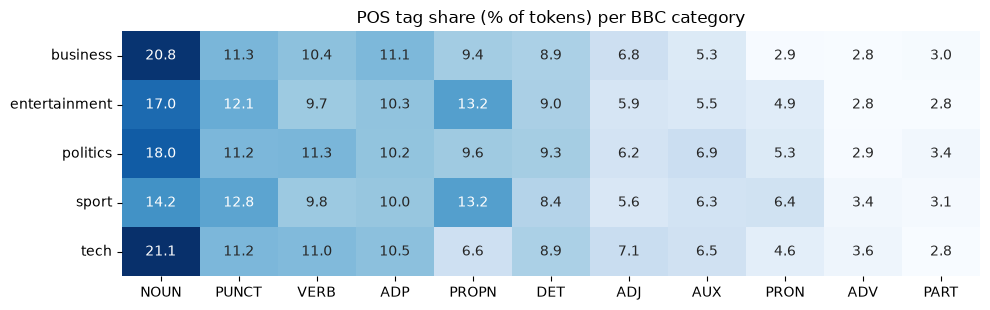

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(pos_share, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
ax.set_title("POS tag share (% of tokens) per BBC category"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Compare the PROPN and NOUN columns. Sport and entertainment stories are full of names (players,
clubs, stars), so they have the most proper nouns. Tech and business have the most common nouns
(products, markets, prices) and tech the fewest names. Sport also has the most pronouns, from quoted
speech ("we", "I"). Function-word tags (DET, ADP) barely move, because grammar does not depend on topic.

## Top-10 PERSON / ORG / GPE per category
A trailing possessive *'s* is stripped so that "Blair's" and "Blair" count together.

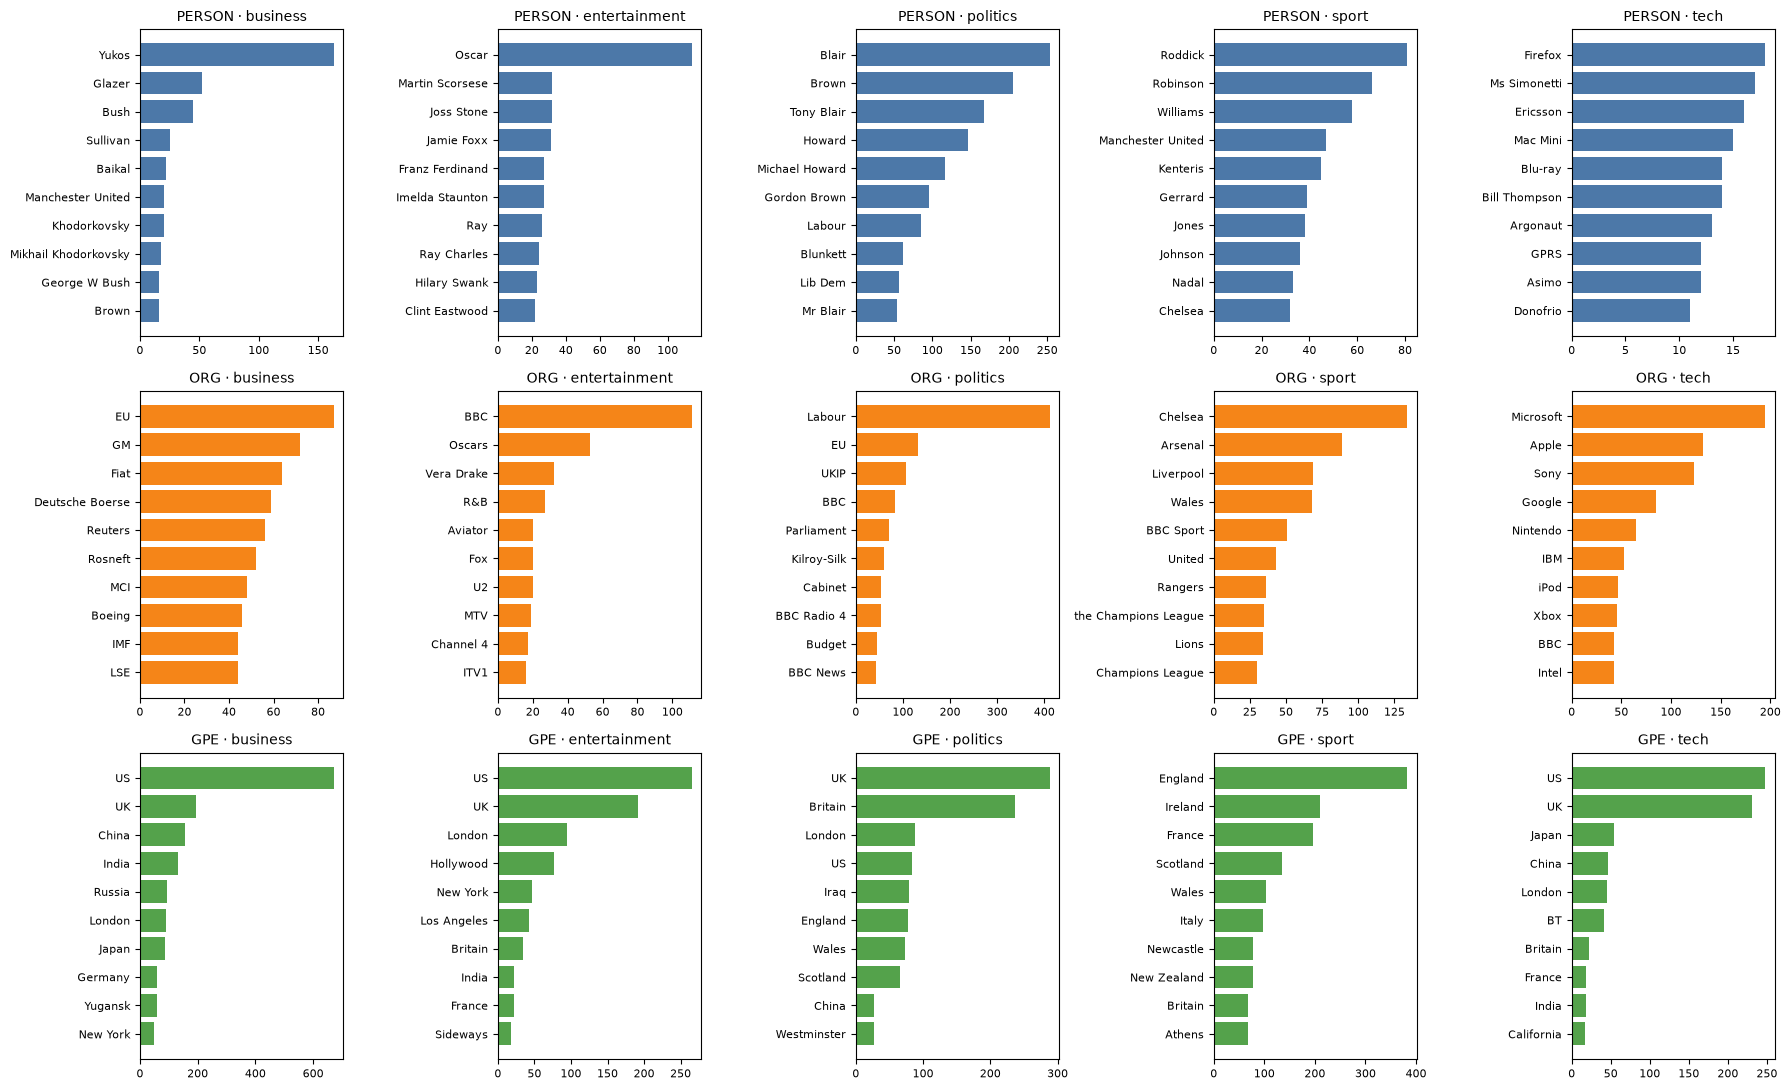

In [6]:
ents["norm"] = ents.text.str.replace(r"['’]s$", "", regex=True).str.strip()
fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for r, label in enumerate(["PERSON", "ORG", "GPE"]):
    for c, cat in enumerate(BBC_LABELS):
        top = ents[(ents.label == label) & (ents.category == cat)].norm.value_counts().head(10)[::-1]
        ax = axes[r, c]
        ax.barh(top.index, top.values, color=["#4C78A8", "#F58518", "#54A24B"][r])
        ax.set_title(f"{label} · {cat}", fontsize=10); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

**The charts expose NER errors at corpus scale.** Mostly the lists are right (Blair, Brown and Howard in
politics; Microsoft, Apple and Sony in tech). But several top "PERSON"s are not people:
*Yukos* (an oil company) tops business, and *Oscar*, *Firefox*, *Mac Mini*, *Blu-ray*, *Labour* and
*Chelsea* all appear. Clubs and national teams switch between ORG, PERSON and GPE (*Wales*,
*Newcastle*), and *BT* (a company) and *Sideways* (a film) show up as GPE. The same person is also
split into "Blair", "Tony Blair" and "Mr Blair": NER finds mentions, but linking them to one entity
(coreference / entity linking) is a separate task.

## displaCy: entities in 2 sentences

In [7]:
sent_a = ("Mexican outfit Red Sharks Veracruz hope to sign Juninho if the Brazilian decides to leave "
          "Celtic frustrated at his lack of first-team action.")
sent_b = ("The World Anti-Doping Agency (Wada) will appeal against the acquittal of Kostas Kenteris and "
          "Katerina Thanou on doping charges, if the IAAF does not.")
for s in [sent_a, sent_b]:
    displacy.render(nlp(s), style="ent", jupyter=True)

Both already show errors: the club *Red Sharks Veracruz* is tagged PERSON and the player *Juninho*
ORG, *Wada* is tagged GPE, and *IAAF* is missed entirely.

## NLTK vs spaCy POS tags on 10 sentences
Both tag the same (spaCy) tokens with Penn Treebank tags (`token.tag_` in spaCy, `nltk.pos_tag`).
Punctuation is left out: the two libraries use different *names* for the same symbols
(NLTK `:` vs spaCy `HYPH` for "-", `(` vs `-LRB-`), which is a naming convention, not a disagreement.
"Coarse" agreement compares only the first two letters (NN*, VB*, JJ*…), so NN vs NNS counts as agreeing.

In [8]:
check = load("bbc").groupby("category").sample(6, random_state=SEED)  # same 30 articles as the NER check below
sentences = [nltk.sent_tokenize(b)[0] for b in check.body]

agree_rows, disagreements = [], []
for s in sentences[:10]:
    doc = nlp(s)
    nltk_all = [t for _, t in nltk.pos_tag([t.text for t in doc])]  # tag the full sentence...
    keep = [i for i, t in enumerate(doc) if not t.is_punct]           # ...then drop punctuation
    toks = [doc[i].text for i in keep]
    nltk_tags = [nltk_all[i] for i in keep]
    spacy_tags = [doc[i].tag_ for i in keep]
    fine = sum(a == b for a, b in zip(nltk_tags, spacy_tags))
    coarse = sum(a[:2] == b[:2] for a, b in zip(nltk_tags, spacy_tags))
    agree_rows.append({"sentence": s[:70] + "…", "tokens": len(toks),
                       "fine agree %": round(100 * fine / len(toks), 1),
                       "coarse agree %": round(100 * coarse / len(toks), 1)})
    disagreements += [(w, a, b) for w, a, b in zip(toks, nltk_tags, spacy_tags) if a != b]
agree = pd.DataFrame(agree_rows)
total = agree.tokens.sum()
fine_all = (agree["fine agree %"] * agree.tokens).sum() / total
coarse_all = (agree["coarse agree %"] * agree.tokens).sum() / total
print(f"overall: fine {fine_all:.1f}%  coarse {coarse_all:.1f}%  over {total} word tokens")
agree

overall: fine 94.3%  coarse 94.8%  over 229 word tokens


,sentence,tokens,fine agree %,coarse agree %
0,A strike on the Buenos Aires underground has caused traffic chaos and …,21,90.5,90.5
1,Indonesia's government has confirmed it is considering raising fuel pr…,16,100.0,100.0
2,Scandal-hit jet fuel supplier China Aviation Oil has offered to repay …,32,87.5,90.6
3,The US budget deficit is set to hit a worse-than-expected $368bn (£197…,22,90.9,90.9
4,"News Corp, the media company controlled by Australian billionaire Rupe…",20,100.0,100.0
5,"Three years after a gruelling economic crisis, Turkey has dressed its …",14,100.0,100.0
6,Novelist Andrea Levy is favourite to win the main Whitbread Prize book…,27,100.0,100.0
7,The reggae industry is to refuse to release or stage concerts featurin…,23,91.3,91.3
8,The parents of a 13-year-old girl are suing US supermarket giant Wal-M…,26,96.2,96.2
9,"The new big-screen version of The Magic Roundabout, released in the UK…",28,92.9,92.9


In [9]:
pd.DataFrame(disagreements, columns=["token", "NLTK", "spaCy"]).head(20)

,token,NLTK,spaCy
0,underground,NN,RB
1,Argentine,NNP,JJ
2,Scandal,NNP,NN
3,hit,NN,VBN
4,£,JJ,$
5,m,NN,CD
6,368bn,CD,NN
7,197bn,CD,NNS
8,stage,VB,NN
9,struck,NN,VBN


Typical disagreements: words that can be a participle, noun or adjective ("hit", "struck", "stage"),
nationality words (*Argentine*: NNP vs JJ), and money tokens (*£*, *368bn*). Neither tagger is "right"
by default; they were trained on different data with different models.

## NER error analysis: 30 hand-checked sentences
The first sentence of 6 random articles per category (seed 42). Each predicted entity was checked
by hand against the OntoNotes guidelines spaCy was trained on, and missed entities were noted.

⚠️ **The hand check below was done by the AI assistant. Review it yourself before the viva.**

`WRONG[i]` maps a *predicted* entity text to what is wrong with it; `MISSED[i]` lists entities
spaCy did not find. An assert confirms every "wrong" entity really is in spaCy's output.

In [10]:
WRONG = {
    2: {"220": "span: should be '$220m'", "117": "span: should be '£117m'", "550": "span: should be '$550m'"},
    3: {"368bn": "span: '$' left out", "197bn": "type: MONEY tagged PERSON"},
    6: {"Novelist Andrea Levy": "span: job title included", "Whitbread Prize": "type: a prize, not an ORG",
        "the year award": "false DATE (part of 'book of the year award')",
        "the year": "false DATE ('novel of the year')", "Small Island": "type: book title (WORK_OF_ART), not LOC"},
    8: {"Evanescence": "type: rock band is ORG, not PERSON"},
    10: {"25": "span: should be '$25m'", "13": "span: should be '£13m'"},
    11: {"Blackadder": "type: TV comedy (WORK_OF_ART), not PERSON"},
    17: {"Tony Blair's": "span: possessive 's included"},
    18: {"Red Sharks Veracruz": "type: football club is ORG, not PERSON",
         "Juninho": "type: player is PERSON, not ORG"},
    19: {"Olympic": "type: not a facility (FAC)", "100": "span/type: '100m' is a race distance (QUANTITY)"},
    21: {"the World Cross Country Championships": "type: an EVENT, not ORG"},
    22: {"Wada": "type: agency acronym is ORG, not GPE"},
    23: {"Titus Bramble's": "span: possessive 's included",
         "Newcastle": "type: the football club (ORG), yet 'Liverpool' in the same sentence is ORG",
         "Anfield": "type: a stadium (FAC), not ORG"},
    24: {"a big year": "false DATE"},
    25: {"Sci-fi": "false ORG (a genre)"},
    26: {"Windows": "type: software (PRODUCT), not LOC"},
    27: {"3": "false CARDINAL: part of '3G', a technology name"},
}
MISSED = {22: ["IAAF (ORG)"], 25: ["Doom 3 (PRODUCT/WORK_OF_ART)", "Golden Joystick awards (EVENT)"]}

rows = []
for i, s in enumerate(sentences):
    predicted = [(e.text, e.label_) for e in nlp(s).ents]
    wrong = WRONG.get(i, {})
    assert set(wrong) <= {t for t, _ in predicted}, f"sentence {i}: spaCy output changed, re-check by hand"
    rows.append({"i": i, "category": check.category.iloc[i], "sentence": s, "predicted": predicted,
                 "n_pred": len(predicted), "n_wrong": len(wrong), "n_missed": len(MISSED.get(i, [])),
                 "problems": list(wrong.values()) + [f"missed {m}" for m in MISSED.get(i, [])]})
ner_check = pd.DataFrame(rows)
n_pred, n_wrong, n_missed = ner_check.n_pred.sum(), ner_check.n_wrong.sum(), ner_check.n_missed.sum()
bad_sents = int(((ner_check.n_wrong + ner_check.n_missed) > 0).sum())
ner_stats = {"sentences": len(ner_check), "sentences_with_error": bad_sents,
             "predicted_entities": int(n_pred), "wrong_entities": int(n_wrong), "missed_entities": int(n_missed),
             "precision_exact": round(float(1 - n_wrong / n_pred), 3)}
print(ner_stats)
per_cat = ner_check.groupby("category")[["n_pred", "n_wrong", "n_missed"]].sum()
per_cat

{'sentences': 30, 'sentences_with_error': 16, 'predicted_entities': 85, 'wrong_entities': 28, 'missed_entities': 3, 'precision_exact': 0.671}


,n_pred,n_wrong,n_missed
category,,,
business,18,5,0
entertainment,20,9,0
politics,10,1,0
sport,28,9,1
tech,9,4,2


### 5 wrong cases and why

In [11]:
for i in [3, 18, 23, 6, 25]:
    r = ner_check.iloc[i]
    print(f"[{i}] {r.sentence}\n     spaCy: {r.predicted}\n     problems: {r.problems}\n")

[3] The US budget deficit is set to hit a worse-than-expected $368bn (£197bn) this year, officials said on Tuesday.
     spaCy: [('US', 'GPE'), ('368bn', 'MONEY'), ('197bn', 'PERSON'), ('this year', 'DATE'), ('Tuesday', 'DATE')]
     problems: ["span: '$' left out", 'type: MONEY tagged PERSON']

[18] Mexican outfit Red Sharks Veracruz hope to sign Juninho if the Brazilian decides to leave Celtic frustrated at his lack of first-team action.
     spaCy: [('Mexican', 'NORP'), ('Red Sharks Veracruz', 'PERSON'), ('Juninho', 'ORG'), ('Brazilian', 'NORP'), ('Celtic', 'ORG'), ('first', 'ORDINAL')]
     problems: ['type: football club is ORG, not PERSON', 'type: player is PERSON, not ORG']

[23] Titus Bramble's own goal put Liverpool on the comeback trail as injury-hit Newcastle were well beaten at Anfield.
     spaCy: [("Titus Bramble's", 'PERSON'), ('Liverpool', 'ORG'), ('Newcastle', 'GPE'), ('Anfield', 'ORG')]
     problems: ["span: possessive 's included", "type: the football club (ORG), ye

Why these happen:
1. **[3] "197bn" → PERSON.** In "$368bn (£197bn)" the tokenizer splits off the currency symbol, and
   the small model sees an unusual capitalised-looking token in brackets. It has no rule saying
   "number + bn is money".
2. **[18] club and player swapped.** Both are unfamiliar proper nouns. The model relies on context
   ("hope to sign X", "leave Celtic"), and here the context misled it. The small model has no
   knowledge base behind it.
3. **[23] Newcastle GPE vs Liverpool ORG.** *Metonymy*: a city name used to mean its football club.
   The same kind of name gets different labels in the same sentence, which shows the model is guessing
   from local context.
4. **[6] "the year" → DATE.** OntoNotes marks many "year" phrases as DATE, so the model over-applies
   the pattern to award names ("novel of the year").
5. **[25] missed "Doom 3", false "Sci-fi".** Product and game names are rare in OntoNotes news, and a
   capitalised genre word at sentence start looks like a name.

Span errors (currency, possessive *'s*) are systematic, so they could be fixed with a rule. The type
errors need a larger model (`en_core_web_trf`) or domain training data.

In [12]:
save_results("pos_ner", {
    "dataset": "bbc", "n_articles": len(bbc), "n_tokens": n_tokens, "n_entities": len(ents),
    "seconds": round(secs, 1), "pos_share_pct": pos_share.to_dict(),
    "entity_label_counts": ents.label.value_counts().to_dict(),
    "nltk_spacy_pos_agreement": {"fine_pct": round(fine_all, 1), "coarse_pct": round(coarse_all, 1),
                                 "tokens": int(total)},
    "ner_hand_check": ner_stats, "ner_hand_check_by": "AI assistant; to be reviewed by student",
})

saved results/pos_ner.json


PosixPath('/Users/mihirmandavia/nlp-news/results/pos_ner.json')

## Viva notes
**Q1. What is the difference between POS tagging and NER?**
POS tagging gives *every* token a grammatical tag. NER finds *spans* (possibly several tokens,
e.g. "Red Sharks Veracruz") that name something, and gives each span a type. Both are sequence
labelling; NER is usually encoded with BIO tags (B-ORG, I-ORG, O).

**Q2. Why do NLTK and spaCy disagree on some tags?**
They are different models (averaged perceptron vs CNN) trained on different corpora (WSJ Penn
Treebank vs OntoNotes). Ambiguous words (participle vs adjective, capitalised sentence-initial words)
get different tags. Compare the fine and coarse agreement printed above; punctuation is excluded,
because the libraries only name those tags differently.

**Q3. Why did spaCy label "Newcastle" as GPE?**
Metonymy: a city name used for its football club. `en_core_web_sm` decides from nearby words
and has no world knowledge, so it picks the more frequent reading of the name (a place).